# Benford's Law & digit tests — Bulgarian presidential election, round 1 (25 Oct 2026)

**Question:** do the polling-station vote counts carry statistical fingerprints of manipulation?

## What Benford's Law is (and the Bush story)
Benford's Law says that in many naturally occurring datasets the leading digit $d$ appears with probability
$P(d) = \log_{10}(1 + 1/d)$: a **1** leads ~30% of the time, a **9** only ~4.6%.

The claim you read probably refers to **Walter Mebane**'s work. He applied a *second-digit* Benford test (“2BL”) to precinct
counts from the 2004 US election (and later Iran 2009, Russia, etc.). Two important nuances:

* Mebane did **not** claim the test proved Bush's election was rigged. He was careful to say that deviations can come from
  normal political behaviour (strategic voting, geographic clustering) as well as fraud.
* The *first-digit* test is widely considered **unsuitable** for polling-station data (Deckert, Myagkov & Ordeshook, 2011,
  *Political Analysis*). Polling stations have roughly similar sizes (a few hundred voters), so the leading digit of a candidate's
  count is mostly decided by **station size × vote share**, not by honesty.

So this notebook runs three tests and, crucially, compares each one against a **simulated clean election** that has
exactly the same polling-station sizes and regional preferences. If the real data deviate from Benford *in the same way the clean
simulation does*, the deviation tells us nothing about fraud.

| Test | Idea | Reference |
|---|---|---|
| 1st digit (1BL) | classic Benford | Benford 1938; criticised for elections by Deckert et al. 2011 |
| 2nd digit (2BL) | second digit should follow Benford's 2nd-digit law (mean ≈ 4.187) | Mebane 2006, 2011 |
| Last digit | when people invent numbers, last digits stop being uniform (e.g. too many 0s and 5s) | Beber & Scacco 2012 |
| Round-number heaping | are counts like 20, 50, 100 more frequent than their neighbours 18, 19, 21, 22? | standard “digit preference” check |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from load_data import load_votes, load_sections

votes = load_votes()      # rows = polling stations, cols = candidates (+ "none of the above")
meta = load_sections()
print(votes.shape)

(12719, 28)


In [2]:
# ---- chart style (one consistent visual system for every figure) ----
BLUE, ORANGE = "#2a78d6", "#eb6834"          # observed / expected
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
SIM_FILL = "#c3c2b7"                          # neutral band for the simulated clean election
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})

## 1. Which series to test
Digit tests need numbers that span a wide range. Most of the 27 candidates get single-digit counts in almost every station.
* **Digit tests (1st / 2nd / last digit):** only the **top 3 candidates**, whose counts regularly reach the hundreds.
  For smaller candidates, counts ≥ 10 sit almost entirely in the 10–19 range. So “10” is automatically the most common count ≥ 10, and
  the last digit looks like “too many zeros” and the second digit like “too many small digits”. That is pure arithmetic,
  not fraud (checked below).
* **Round-number heaping:** works for every series, so we use the top 6 candidates, “none of the above” and turnout.

In [3]:
NONE = "Не подкрепям никого"
cand_cols = [c for c in votes.columns if c != NONE]
ranked = list(votes[cand_cols].sum().sort_values(ascending=False).index)
TOP3 = ranked[:3]                 # digit tests
MAIN = ranked[:6] + [NONE]        # heaping test

summary = pd.DataFrame({
    "total votes": votes[MAIN].sum(),
    "median per station": votes[MAIN].median(),
    "stations with ≥10 votes": (votes[MAIN] >= 10).sum(),
    "max in one station": votes[MAIN].max(),
})
summary

,total votes,median per station,stations with ≥10 votes,max in one station
25 Илияна Йотова,528951,40.0,11474,340
04 Андрей Гюров,486232,23.0,8921,418
11 Костадин Костадинов,190910,14.0,7813,96
17 Радостин Василев,70127,5.0,2091,124
19 Ивелин Михайлов,57643,3.0,1569,88
18 Иван Христанов,36407,2.0,579,53
Не подкрепям никого,67353,5.0,1988,116


## 2. Why the first-digit test is suspect: station sizes are bounded
Benford works for data that spread over many orders of magnitude. Polling stations don't: most have between 50 and 600 valid
votes. A candidate with ~35% support therefore gets ~20–200 votes almost everywhere, so the first digit is mostly constrained
by station size.

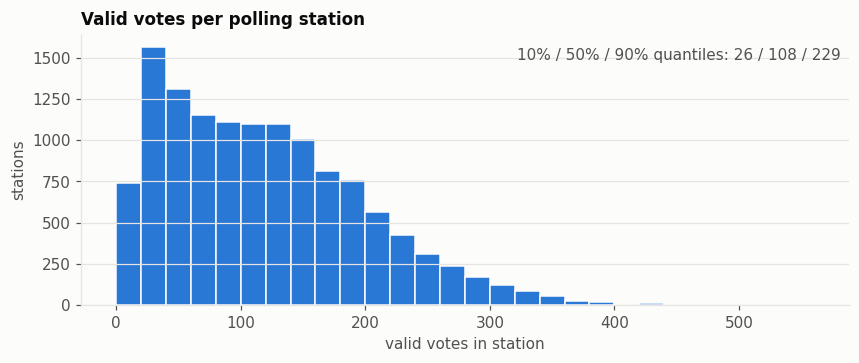

In [4]:
station_size = votes.sum(axis=1)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(station_size, bins=np.arange(0, station_size.max() + 20, 20), color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.set_title("Valid votes per polling station")
ax.set_xlabel("valid votes in station"); ax.set_ylabel("stations")
q = station_size.quantile([.1, .5, .9])
ax.text(0.99, 0.95, f"10% / 50% / 90% quantiles: {q.iloc[0]:.0f} / {q.iloc[1]:.0f} / {q.iloc[2]:.0f}",
        transform=ax.transAxes, ha="right", va="top", color=INK2)
plt.show()

## 3. Digit helpers, Benford expectations and test statistics
* **χ² goodness-of-fit** — with ~10,000 stations even tiny, meaningless deviations become “significant”, so the p-value alone
  is not informative.
* **MAD** (mean absolute deviation of digit proportions, Nigrini) is size-independent. Nigrini's rule of thumb for the first
  digit: < 0.006 close conformity · 0.006–0.012 acceptable · 0.012–0.015 marginal · > 0.015 **nonconformity**.
  For the second digit the thresholds are 0.008 / 0.010 / 0.012.

In [5]:
D1 = np.arange(1, 10)
P1 = np.log10(1 + 1 / D1)                                                          # Benford 1st digit
D2 = np.arange(10)
P2 = np.array([sum(np.log10(1 + 1 / (10 * k + d)) for k in range(1, 10)) for d in D2])   # Benford 2nd digit
P_LAST = np.full(10, 0.1)                                                          # uniform last digit
MEAN_2BL = (D2 * P2).sum()

def first_digit(x):
    x = np.asarray(x); x = x[x > 0]
    return np.array([int(str(v)[0]) for v in x])

def second_digit(x):
    x = np.asarray(x); x = x[x >= 10]
    return np.array([int(str(v)[1]) for v in x])

def last_digit(x, min_value=10):
    x = np.asarray(x); x = x[x >= min_value]
    return x % 10

def digit_test(digits, support, expected):
    counts = np.array([(digits == d).sum() for d in support])
    n = counts.sum()
    obs = counts / n
    chi2, p = stats.chisquare(counts, expected * n)
    return dict(n=n, chi2=chi2, p=p, MAD=np.abs(obs - expected).mean(), obs=obs, mean=digits.mean())

def nigrini(mad, thresholds):
    a, b, c = thresholds
    return "close" if mad < a else "acceptable" if mad < b else "marginal" if mad < c else "NONCONFORMITY"

def results_table(tests, thresholds, extra_mean=None):
    rows = {k: {"n": v["n"], "χ²": v["chi2"], "p-value": v["p"], "MAD": v["MAD"],
                "Nigrini verdict": nigrini(v["MAD"], thresholds)} for k, v in tests.items()}
    df = pd.DataFrame(rows).T
    if extra_mean is not None:
        df.insert(1, "mean digit", [tests[k]["mean"] for k in tests])
        df.insert(2, "expected mean", extra_mean)
    return df

## 4. Baseline: the same election, re-rolled by chance
To know what honest numbers look like **with this particular station structure**, we simulate clean versions of this election
(a *parametric bootstrap*):
* every polling station keeps its **real number of valid votes** and its **real vote shares**;
* the votes are then re-drawn at random (multinomial), as if each voter's ballot were a fresh random draw from that station's
  preferences.

This keeps the coarse shape of the data (station sizes, where each candidate is strong), which is what drives the 1st and 2nd
digits. It erases any fine-grained digit preference a human might have written into a protocol, because re-rolling moves every
count by a few votes. If a real-data “Benford violation” also appears in these clean simulations, it comes from the station
structure, not from cheating.

*Limitation:* re-rolling adds a second dose of random noise, so the simulated distributions are slightly smoother than real
ones. Treat small gaps between real data and the band with caution.

In [6]:
rng = np.random.default_rng(2026)
N_SIM = 100
sizes = station_size.to_numpy()
shares = votes.div(np.maximum(station_size, 1), axis=0).to_numpy()
sims = [pd.DataFrame(rng.multinomial(sizes, shares), index=votes.index, columns=votes.columns) for _ in range(N_SIM)]
print(f"{N_SIM} clean re-rolled elections simulated")

100 clean re-rolled elections simulated


In [7]:
def digit_props(x, digit_fn, support):
    d = digit_fn(np.asarray(x))
    return np.array([(d == k).mean() for k in support])

def sim_band(digit_fn, support, col, lo=5, hi=95):
    props = np.array([digit_props(s[col], digit_fn, support) for s in sims])
    return np.percentile(props, lo, axis=0), np.percentile(props, hi, axis=0)

def digit_grid(cols, digit_fn, support, expected, expected_label, title, extra=None, ylim=None):
    # Observed (bars) vs theoretical law (line) vs clean simulation (grey band), one panel per series.
    series = {c: votes[c] for c in cols} | (extra or {})
    fig, axes = plt.subplots(1, len(series), figsize=(4.2 * len(series), 3.6), sharey=True)
    for ax, (name, x) in zip(np.atleast_1d(axes), series.items()):
        ax.bar(support, digit_props(x, digit_fn, support), width=0.6, color=BLUE, label="observed", zorder=2)
        if name in votes.columns:
            lo, hi = sim_band(digit_fn, support, name)
            ax.fill_between(support, lo, hi, color=SIM_FILL, alpha=0.7, label="clean simulation (90% band)", zorder=1)
        ax.plot(support, expected, color=ORANGE, lw=2, marker="o", ms=5, label=expected_label, zorder=3)
        ax.set_title(name, fontsize=10); ax.set_xticks(support)
        if ylim: ax.set_ylim(*ylim)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    handles = {l: h for a in np.atleast_1d(axes) for h, l in zip(*a.get_legend_handles_labels())}
    fig.legend(handles.values(), handles.keys(), loc="upper right", ncol=3)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

def sim_stat(col, fn):
    vals = np.array([fn(s[col].to_numpy()) for s in sims])
    return np.percentile(vals, 5), np.percentile(vals, 95)

## 5. Test 1 — Benford first digit (1BL)

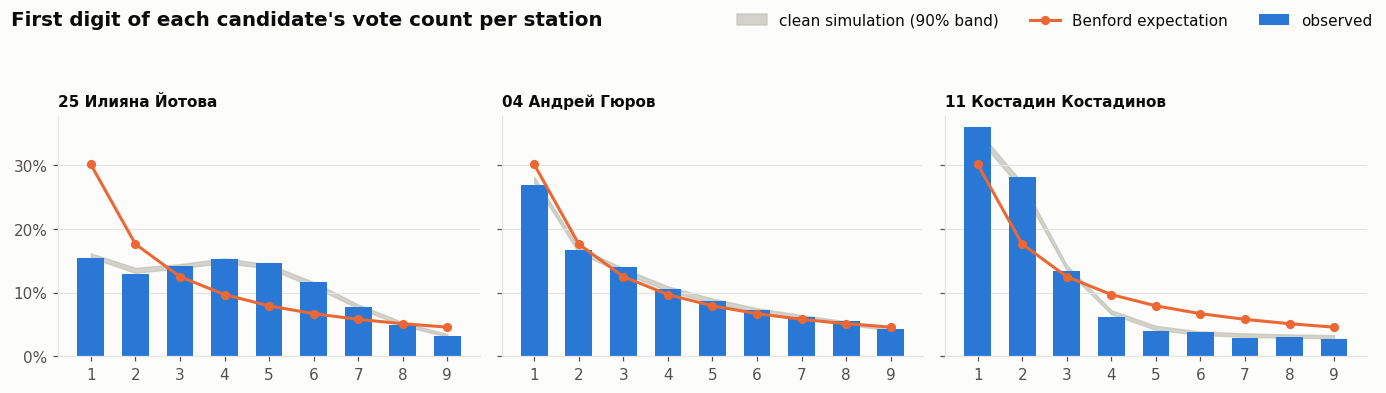

,n,χ²,p-value,MAD,Nigrini verdict,MAD in clean simulations (5–95%)
25 Илияна Йотова,"12,700","2,817",0.0e+00,0.046,NONCONFORMITY,0.043 – 0.045
04 Андрей Гюров,"12,587",108,1.2e-19,0.010,acceptable,0.007 – 0.009
11 Костадин Костадинов,"12,444","1,873",0.0e+00,0.038,NONCONFORMITY,0.033 – 0.035


In [8]:
digit_grid(TOP3, first_digit, D1, P1, "Benford expectation", "First digit of each candidate's vote count per station")

t1 = {c: digit_test(first_digit(votes[c].to_numpy()), D1, P1) for c in TOP3}
tab1 = results_table(t1, (0.006, 0.012, 0.015))
tab1["MAD in clean simulations (5–95%)"] = [
    "{:.3f} – {:.3f}".format(*sim_stat(c, lambda x: digit_test(first_digit(x), D1, P1)["MAD"])) for c in TOP3]
tab1.style.format({"n": "{:,.0f}", "χ²": "{:,.0f}", "p-value": "{:.1e}", "MAD": "{:.3f}"})

**How to read this:** compare the blue bars with the **grey band** (honest elections with the same station structure), not just
with the orange Benford curve. If the clean simulation is *also* far from Benford, the first-digit test can't detect fraud here.

## 6. Test 2 — Mebane's second-digit test (2BL)
Only counts ≥ 10 have a second digit. Under 2BL the second digit's mean is **4.187**. Mebane reads significant departures as
“worth a closer look”, not as proof.

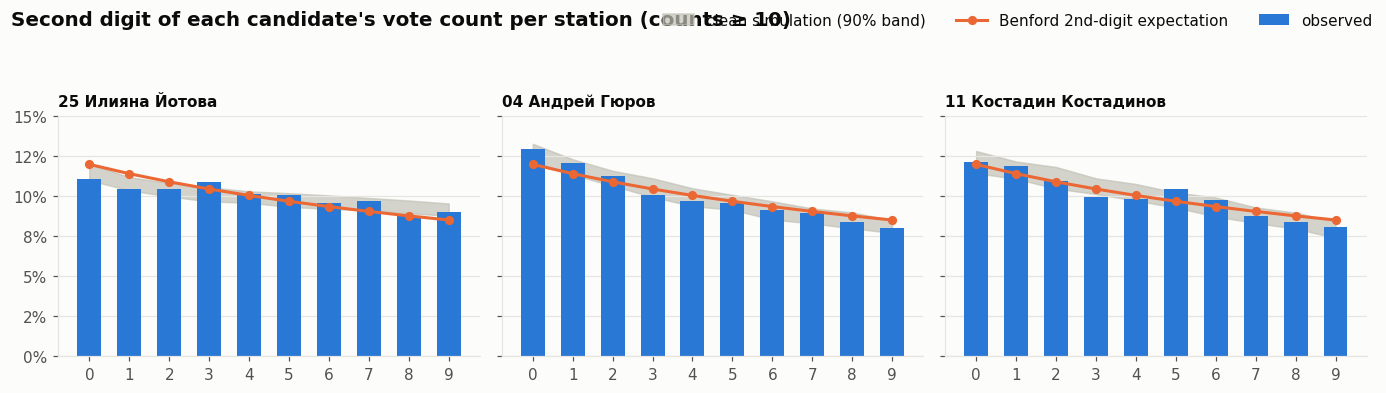

,n,mean digit,expected mean,χ²,p-value,MAD,Nigrini verdict,mean in clean simulations (5–95%)
25 Илияна Йотова,"11,474",4.311,4.187,33.0,1.3e-04,0.0046,close,4.276 – 4.355
04 Андрей Гюров,"8,921",4.077,4.187,18.5,2.9e-02,0.0040,close,4.049 – 4.137
11 Костадин Костадинов,"7,813",4.141,4.187,13.3,1.5e-01,0.0036,close,4.063 – 4.178


In [9]:
digit_grid(TOP3, second_digit, D2, P2, "Benford 2nd-digit expectation",
           "Second digit of each candidate's vote count per station (counts ≥ 10)", ylim=(0, 0.15))

t2 = {c: digit_test(second_digit(votes[c].to_numpy()), D2, P2) for c in TOP3}
tab2 = results_table(t2, (0.008, 0.010, 0.012), extra_mean=MEAN_2BL)
tab2["mean in clean simulations (5–95%)"] = [
    "{:.3f} – {:.3f}".format(*sim_stat(c, lambda x: second_digit(x).mean())) for c in TOP3]
tab2.style.format({"n": "{:,.0f}", "χ²": "{:,.1f}", "p-value": "{:.1e}", "MAD": "{:.4f}",
                   "mean digit": "{:.3f}", "expected mean": "{:.3f}"})

**Why smaller candidates are excluded (quick demonstration):** for a candidate whose counts are mostly 0–20, the second digit
of counts ≥ 10 is just “how far above 10” the count is. A smoothly *decreasing* distribution then has a low mean second digit by
construction. The table shows the 2BL mean for the smaller series is far below 4.187, and is low **in the clean simulations
too**.

In [10]:
small = ranked[3:6] + [NONE]
pd.DataFrame({
    "median count": votes[small].median(),
    "observed 2BL mean": [second_digit(votes[c].to_numpy()).mean() for c in small],
    "clean-sim 2BL mean (5–95%)": ["{:.2f} – {:.2f}".format(*sim_stat(c, lambda x: second_digit(x).mean())) for c in small],
    "Benford 2BL mean": MEAN_2BL,
}).round(3)

,median count,observed 2BL mean,clean-sim 2BL mean (5–95%),Benford 2BL mean
17 Радостин Василев,5.0,2.615,2.74 – 2.90,4.187
19 Ивелин Михайлов,3.0,2.484,2.68 – 2.84,4.187
18 Иван Христанов,2.0,1.845,2.17 – 2.41,4.187
Не подкрепям никого,5.0,2.333,2.59 – 2.76,4.187


## 7. Test 3 — Last-digit uniformity (Beber & Scacco)
When people **make up** numbers they favour certain digits (0, 5, round numbers) and avoid repeats. Honest counts with at least
two digits have nearly uniform last digits (10% each). We also test the **number of voters who signed the voters' list** (turnout),
a number committees write by hand.

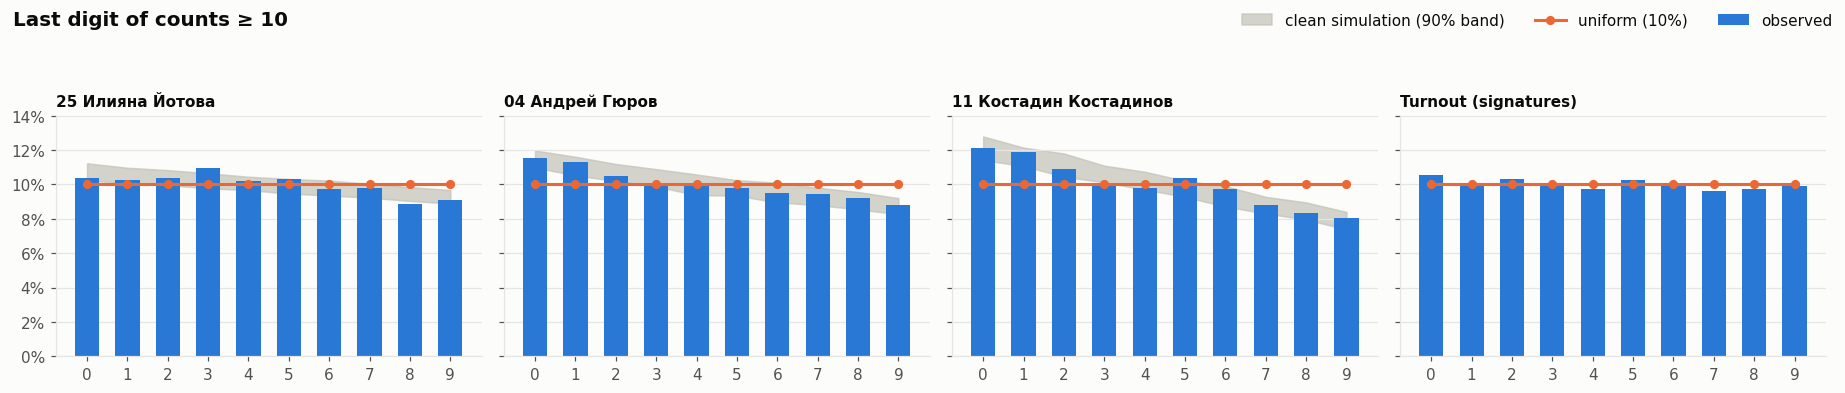

,n,χ²,p-value,ending in 0,ending in 0 or 5,ending in 0 — clean sims (5–95%)
25 Илияна Йотова,"11,474",43.4,1.83e-06,10.4%,20.7%,10.2% – 11.2%
04 Андрей Гюров,"8,921",62.5,4.33e-10,11.5%,21.3%,11.0% – 12.0%
11 Костадин Костадинов,"7,813",133.4,2.39e-24,12.1%,22.5%,11.4% – 12.8%
Turnout (signatures),"12,623",9.7,0.373,10.5%,20.8%,n/a


In [11]:
LAST_MIN = 10
turnout = meta["voted_signatures"].reindex(votes.index)
last = lambda x: last_digit(x, LAST_MIN)

digit_grid(TOP3, last, D2, P_LAST, "uniform (10%)", f"Last digit of counts ≥ {LAST_MIN}",
           extra={"Turnout (signatures)": turnout}, ylim=(0, 0.14))

series3 = {c: votes[c] for c in TOP3} | {"Turnout (signatures)": turnout}
t3 = {k: digit_test(last(s.to_numpy()), D2, P_LAST) for k, s in series3.items()}
tab3 = pd.DataFrame({k: {"n": v["n"], "χ²": v["chi2"], "p-value": v["p"],
                         "ending in 0": v["obs"][0], "ending in 0 or 5": v["obs"][0] + v["obs"][5]}
                     for k, v in t3.items()}).T
tab3["ending in 0 — clean sims (5–95%)"] = [
    "{:.1%} – {:.1%}".format(*sim_stat(k, lambda x: (last(x) == 0).mean())) if k in votes.columns else "n/a" for k in series3]
tab3.style.format({"n": "{:,.0f}", "χ²": "{:.1f}", "p-value": "{:.3g}", "ending in 0": "{:.1%}", "ending in 0 or 5": "{:.1%}"})

## 8. Round-number heaping
This is the most direct check for numbers that were **written in rather than counted**. If committees invented results, counts
like 20, 30, 50 or 100 would show up more often than their neighbours.

**Heaping index** = frequency of counts that are multiples of 10 ÷ average frequency of their neighbours (±1, ±2).
* ≈ 1 → no preference for round numbers. (For a declining distribution it is naturally slightly below 1.)
* clearly > 1 → round numbers are over-represented.

The 95% confidence interval comes from resampling polling stations (bootstrap).

In [12]:
def heaping_index(x, base=10, max_val=None):
    x = np.asarray(x); x = x[x >= 0]
    f = np.bincount(x, minlength=(max_val or x.max()) + 3)
    m = np.arange(base, len(f) - 2, base)
    if base == 5: m = m[m % 10 != 0]           # multiples of 5 that are not multiples of 10
    neigh = (f[m - 2] + f[m - 1] + f[m + 1] + f[m + 2]) / 4
    return f[m].sum() / neigh.sum()

def heaping_ci(x, base=10, n_boot=500):
    x = np.asarray(x); mx = x.max()
    boots = [heaping_index(rng.choice(x, len(x)), base, mx) for _ in range(n_boot)]
    return np.percentile(boots, [2.5, 97.5])

heap_series = {c: votes[c] for c in MAIN} | {"Turnout (signatures)": turnout.dropna().astype(int)}
rows = {}
for name, x in heap_series.items():
    lo10, hi10 = heaping_ci(x, 10); lo5, hi5 = heaping_ci(x, 5)
    rows[name] = {"index ×10": heaping_index(x, 10), "95% CI ×10": f"{lo10:.2f} – {hi10:.2f}",
                  "index ×5": heaping_index(x, 5), "95% CI ×5": f"{lo5:.2f} – {hi5:.2f}"}
heap = pd.DataFrame(rows).T
heap.style.format({"index ×10": "{:.3f}", "index ×5": "{:.3f}"})

,index ×10,95% CI ×10,index ×5,95% CI ×5
25 Илияна Йотова,0.995,0.93 – 1.06,1.019,0.96 – 1.08
04 Андрей Гюров,0.986,0.92 – 1.05,1.004,0.94 – 1.06
11 Костадин Костадинов,1.004,0.93 – 1.08,1.009,0.95 – 1.06
17 Радостин Василев,0.891,0.81 – 0.98,1.028,0.97 – 1.08
19 Ивелин Михайлов,0.961,0.86 – 1.06,1.004,0.93 – 1.07
18 Иван Христанов,0.847,0.72 – 1.01,0.939,0.87 – 1.02
Не подкрепям никого,0.910,0.83 – 1.00,0.983,0.93 – 1.05
Turnout (signatures),1.046,0.99 – 1.10,1.042,0.98 – 1.11


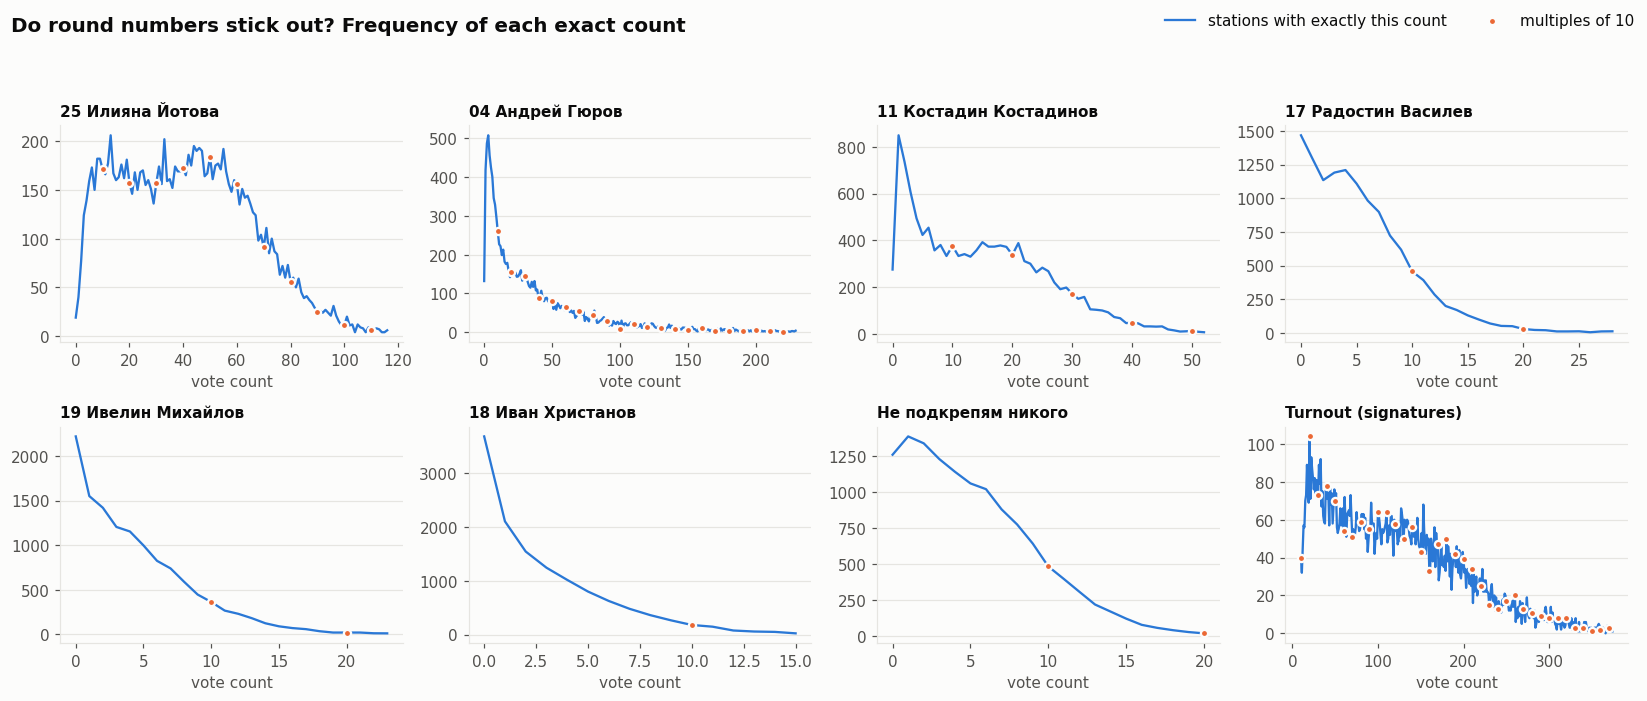

In [13]:
# Visual check: how often each exact count occurs; multiples of 10 highlighted.
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for ax, (name, x) in zip(axes.flat, heap_series.items()):
    x = np.asarray(x)
    hi = int(np.percentile(x, 99.5))
    lo = 10 if name.startswith("Turnout") else 0
    f = np.bincount(x, minlength=hi + 1)[: hi + 1]
    k = np.arange(hi + 1)
    ax.plot(k[lo:], f[lo:], color=BLUE, lw=1.5, label="stations with exactly this count")
    m = k[(k % 10 == 0) & (k >= max(lo, 10))]
    ax.scatter(m, f[m], color=ORANGE, s=22, zorder=3, edgecolor=SURFACE, linewidth=1.5, label="multiples of 10")
    ax.set_title(name, fontsize=10); ax.set_xlabel("vote count")
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2)
fig.suptitle("Do round numbers stick out? Frequency of each exact count", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

## 9. Where? Second-digit test by electoral region
A national test can hide a local problem. For each region (МИР) × top-3 candidate we compare the real mean second digit with the
**same statistic in the 100 clean simulations of that region** and express the gap as a z-score.
Red = higher than the clean simulations, blue = lower.

With 32 regions × 3 candidates = 96 cells, we expect about **4–5 cells beyond |z| > 2** and **~0.3 beyond |z| > 3** purely by chance.

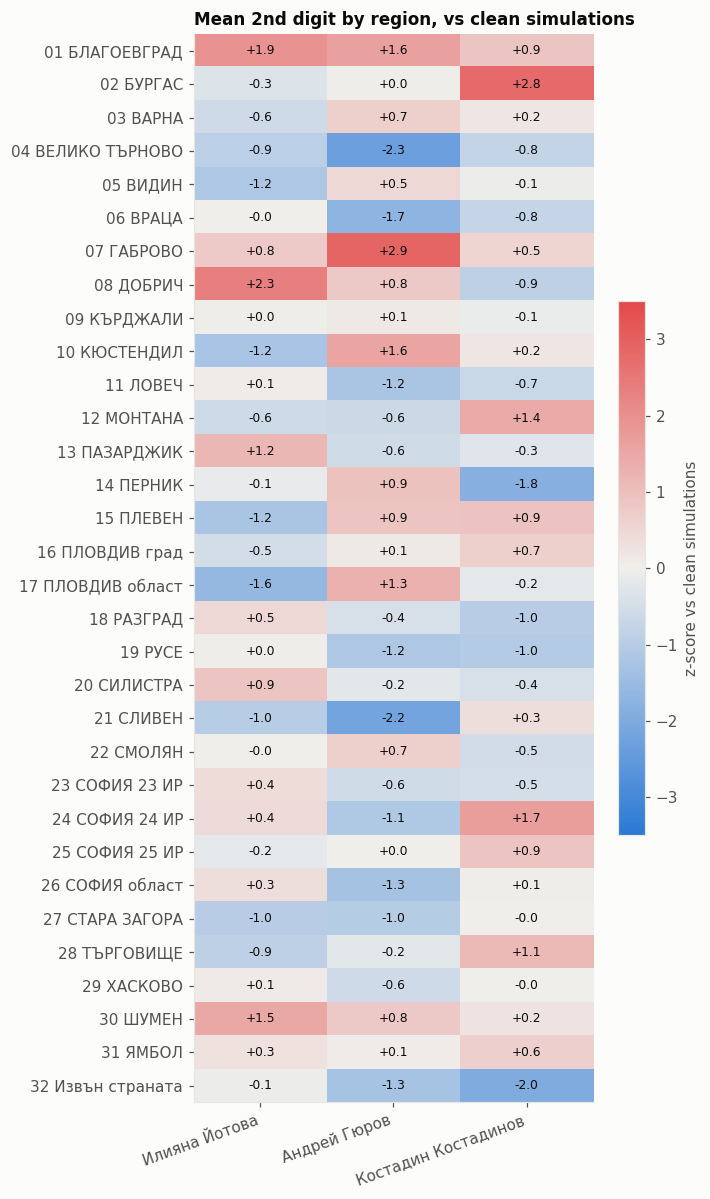

|z| > 2: 5 cells (≈4.4 expected by chance);  |z| > 3: 0 (≈0.3 expected)


02 БУРГАС          11 Костадин Костадинов    2.79
04 ВЕЛИКО ТЪРНОВО  04 Андрей Гюров          -2.33
07 ГАБРОВО         04 Андрей Гюров           2.89
08 ДОБРИЧ          25 Илияна Йотова          2.34
21 СЛИВЕН          04 Андрей Гюров          -2.16
dtype: float64

In [14]:
region = meta["region"].reindex(votes.index)
region_name = meta.groupby("region")["admin_name"].first().str.replace(r"^\d+\.\s*", "", regex=True)

def mean2(x):
    d = second_digit(x)
    return d.mean() if len(d) >= 30 else np.nan

Z = {}
for c in TOP3:
    obs = votes.groupby(region)[c].apply(lambda s: mean2(s.to_numpy()))
    sim = pd.concat([s.groupby(region)[c].apply(lambda s: mean2(s.to_numpy())) for s in sims], axis=1)
    Z[c] = (obs - sim.mean(axis=1)) / sim.std(axis=1)
Z = pd.DataFrame(Z)
Z.index = [f"{r:02d} {region_name[r]}" for r in Z.index]

fig, ax = plt.subplots(figsize=(6.5, 11))
lim = max(3.5, np.nanmax(np.abs(Z.values)))
im = ax.imshow(Z.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(TOP3)), [c.split(" ", 1)[-1] for c in TOP3], rotation=20, ha="right")
ax.set_yticks(range(len(Z)), Z.index); ax.grid(False)
for (i, j), z in np.ndenumerate(Z.values):
    if not np.isnan(z):
        ax.text(j, i, f"{z:+.1f}", ha="center", va="center", fontsize=8, color=INK)
fig.colorbar(im, ax=ax, shrink=0.5, label="z-score vs clean simulations")
ax.set_title("Mean 2nd digit by region, vs clean simulations")
plt.tight_layout(); plt.show()

flat = Z.stack()
print(f"|z| > 2: {(flat.abs() > 2).sum()} cells (≈4.4 expected by chance);  |z| > 3: {(flat.abs() > 3).sum()} (≈0.3 expected)")
flat[flat.abs() > 2].round(2)

## 10. Conclusions

| Test | Raw verdict vs. theory | Compared with clean simulations | Signal of manipulation? |
|---|---|---|---|
| **1st digit (Benford)** | Йотова & Костадинов: “NONCONFORMITY” (MAD 0.046, 0.038) | Clean re-rolled elections are *just as non-Benford* (MAD 0.043–0.045, 0.033–0.035) | **No.** The deviation comes from station sizes × vote share. |
| **2nd digit (Mebane 2BL)** | All three top candidates “close conformity” | Means inside the clean-simulation range | **No** |
| **Last digit** | χ² rejects uniformity for the top 3 | The gentle downward slope 0→9 is reproduced by the clean simulations (it comes from declining count distributions). Turnout last digits are uniform (p = 0.37). | **No** |
| **Round-number heaping** | No series has a heaping index significantly above 1 | — | **No.** Turnout is the closest (1.05, CI 0.99–1.10): not significant, but the one number worth watching. |
| **Regional 2BL** | 5 region×candidate cells with \|z\| > 2, none > 3 | ≈4.4 and ≈0.3 expected by chance | **No regional hotspot** |

### Bottom line
**The digit-based tests find no statistical fingerprint of fabricated numbers in this election.** The “Benford violations” you'd
get from a naive first-digit test are real but meaningless: an honest election with the same polling stations shows exactly the
same violations. This is why the first-digit test is discredited for polling-station data, and why headlines like
“Benford proves election X was rigged” should be read sceptically.

### What these tests *cannot* see
Digit tests only catch **invented numbers** (a committee writing a result in the protocol without counting). They are blind to
fraud where real ballots are cast, which is the usual concern in Bulgaria:
* **vote buying / controlled voting:** real voters, real ballots, real counts;
* **ballot stuffing roughly in proportion to real votes;**
* **carousel voting, pressure on dependent voters.**

So “no digit anomaly” means *the protocols look like honestly counted numbers*. It does not mean *the election was clean*.

### Better next heuristics
1. **Turnout vs. vote-share fingerprint** (Klimek et al., *PNAS* 2012): stations with suspiciously high turnout where one
   candidate also gets an extreme share.
2. **Outlier stations:** turnout near 100%, one candidate with 90%+, big jumps in voters added on election day (“under the line”).
3. **Paper vs machine:** within the same municipality, do paper-ballot results differ systematically from machine votes?
4. **Protocol arithmetic:** inconsistencies between ballots received, used, unused and votes cast.
5. **Machine data (`suemg/`) vs protocols:** whether the machine flash-drive results match what was entered in the protocols.